# Project 1 — Wholesale Customers: Segmenting Customers by Spending Behaviour (Clustering)

**Course:** DSC8307 Data Mining, Modeling and Analytics — Assignment 2

**Student name:** NAMUYOMBA NAKACHWA EMILLY
**Registration number:** S25M19/047
**Access number:** B35963



## Executive summary

**Goal.** Group 440 wholesale customers by how they spend across six product categories, and recommend how to serve each group.

**Main results**
- **Data and preparation.** Spending is extremely skewed (skewness up to 11) and categories differ greatly in size. Spending was **log-transformed and standardised**. There are no missing values, duplicates or zeros. Unusually large or small customers were kept, and their effect was tested.
- **Cluster tendency.** Hopkins statistic **H ≈ 0.79** (uniform random data: 0.49). There is real structure, though not sharply separated.
- **Comparison of the three clustering families**
  - **Partitioning (k-means)** gives the best balance of quality and interpretability: silhouette 0.26 at k = 3 (0.29 at k = 2), and the most stable solution (bootstrap ARI 0.79). Its centroids translate directly into "typical spending" per segment. k-medoids was clearly weaker here.
  - **Hierarchical:** **Ward linkage** finds similar segments (ARI 0.69 with k-means). Single and average linkage only split off 1–2 extreme customers ("chaining"). Their high silhouette (≈0.55) is therefore misleading.
  - **Density-based (DBSCAN)** finds **one dense core** plus **42 unusual customers** for every reasonable setting. It doesn't segment this data, but it is useful for flagging exceptional accounts.
- **Three named segments (k-means, k = 3):**
  - **"Fresh-food caterers"**: 211 customers, 99% Horeca.
  - **"Large all-round buyers"**: 148 customers, the highest spenders in every category.
  - **"Grocery & household specialists"**: 81 customers, who buy groceries, milk and detergents but almost no fresh or frozen food.
- **Robustness.** The two-way split between "kitchen" customers and "shop" customers is very robust (ARI 0.96 without the unusual customers). The three-segment version is reasonably robust (0.86).


In [175]:
## Set-up and reproducibility
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from pandas.api.types import is_numeric_dtype
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0 | scipy 1.17.1


In [176]:

wholesale = pd.read_csv("wholesale-customers.csv")
wholesale

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [177]:
SPEND = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]
wholesale["Channel_name"] = wholesale["Channel"].map({1: "Horeca", 2: "Retail"})
wholesale["Region_name"] = wholesale["Region"].map({1: "Lisbon", 2: "Oporto", 3: "Other"})
print("Number of customers = %d, number of attributes = %d" % (wholesale.shape[0], 8))
wholesale.head()

Number of customers = 440, number of attributes = 8


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Channel_name,Region_name
0,2,3,12669,9656,7561,214,2674,1338,Retail,Other
1,2,3,7057,9810,9568,1762,3293,1776,Retail,Other
2,2,3,6353,8808,7684,2405,3516,7844,Retail,Other
3,1,3,13265,1196,4221,6404,507,1788,Horeca,Other
4,2,3,22615,5410,7198,3915,1777,5185,Retail,Other


In [178]:
wholesale.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
 8   Channel_name      440 non-null    str  
 9   Region_name       440 non-null    str  
dtypes: int64(8), str(2)
memory usage: 34.5 KB


In [179]:
wholesale.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.000,440.000,440.000,440.000,440.000,440.000,440.000,440.000
mean,1.323,2.543,"12,000.298","5,796.266","7,951.277","3,071.932","2,881.493","1,524.870"
std,0.468,0.774,"12,647.329","7,380.377","9,503.163","4,854.673","4,767.854","2,820.106"
min,1.000,1.000,3.000,55.000,3.000,25.000,3.000,3.000
25%,1.000,2.000,"3,127.750","1,533.000","2,153.000",742.250,256.750,408.250
50%,1.000,3.000,"8,504.000","3,627.000","4,755.500","1,526.000",816.500,965.500
75%,2.000,3.000,"16,933.750","7,190.250","10,655.750","3,554.250","3,922.000","1,820.250"
max,2.000,3.000,"112,151.000","73,498.000","92,780.000","60,869.000","40,827.000","47,943.000"


In [180]:
### Summary statistics
for col in SPEND:
    print('%s:' % col)
    print('\t Mean = %.2f' % wholesale[col].mean())
    print('\t Median = %.2f' % wholesale[col].median())
    print('\t Standard deviation = %.2f' % wholesale[col].std())
    print('\t Minimum = %.2f' % wholesale[col].min())
    print('\t Maximum = %.2f' % wholesale[col].max())
    print('\t Skewness = %.2f' % wholesale[col].skew())

Fresh:
	 Mean = 12000.30
	 Median = 8504.00
	 Standard deviation = 12647.33
	 Minimum = 3.00
	 Maximum = 112151.00
	 Skewness = 2.56
Milk:
	 Mean = 5796.27
	 Median = 3627.00
	 Standard deviation = 7380.38
	 Minimum = 55.00
	 Maximum = 73498.00
	 Skewness = 4.05
Grocery:
	 Mean = 7951.28
	 Median = 4755.50
	 Standard deviation = 9503.16
	 Minimum = 3.00
	 Maximum = 92780.00
	 Skewness = 3.59
Frozen:
	 Mean = 3071.93
	 Median = 1526.00
	 Standard deviation = 4854.67
	 Minimum = 25.00
	 Maximum = 60869.00
	 Skewness = 5.91
Detergents_Paper:
	 Mean = 2881.49
	 Median = 816.50
	 Standard deviation = 4767.85
	 Minimum = 3.00
	 Maximum = 40827.00
	 Skewness = 3.63
Delicatessen:
	 Mean = 1524.87
	 Median = 965.50
	 Standard deviation = 2820.11
	 Minimum = 3.00
	 Maximum = 47943.00
	 Skewness = 11.15


In [181]:
print(wholesale["Channel_name"].value_counts().to_string(), "\n")
print(wholesale["Region_name"].value_counts().to_string())

Channel_name
Horeca    298
Retail    142 

Region_name
Other     316
Lisbon     77
Oporto     47


**Explanation**
- **All six spending columns are strongly right-skewed.** Each mean is far above its median: Fresh averages about 12,000 m.u. against a median of 8,504. Skewness ranges from 2.6 (Fresh) to **11.2 (Delicatessen)**, where one customer spends 47,943 m.u. against a median of 966.
- **Magnitudes differ a lot between categories.** Fresh is the largest category on average, Delicatessen the smallest. Distance-based clustering would therefore be dominated by Fresh unless the attributes are put on a common scale.
- **There are 298 Horeca and 142 Retail customers**, and most customers are in the "Other" region (316 vs 77 Lisbon and 47 Oporto).



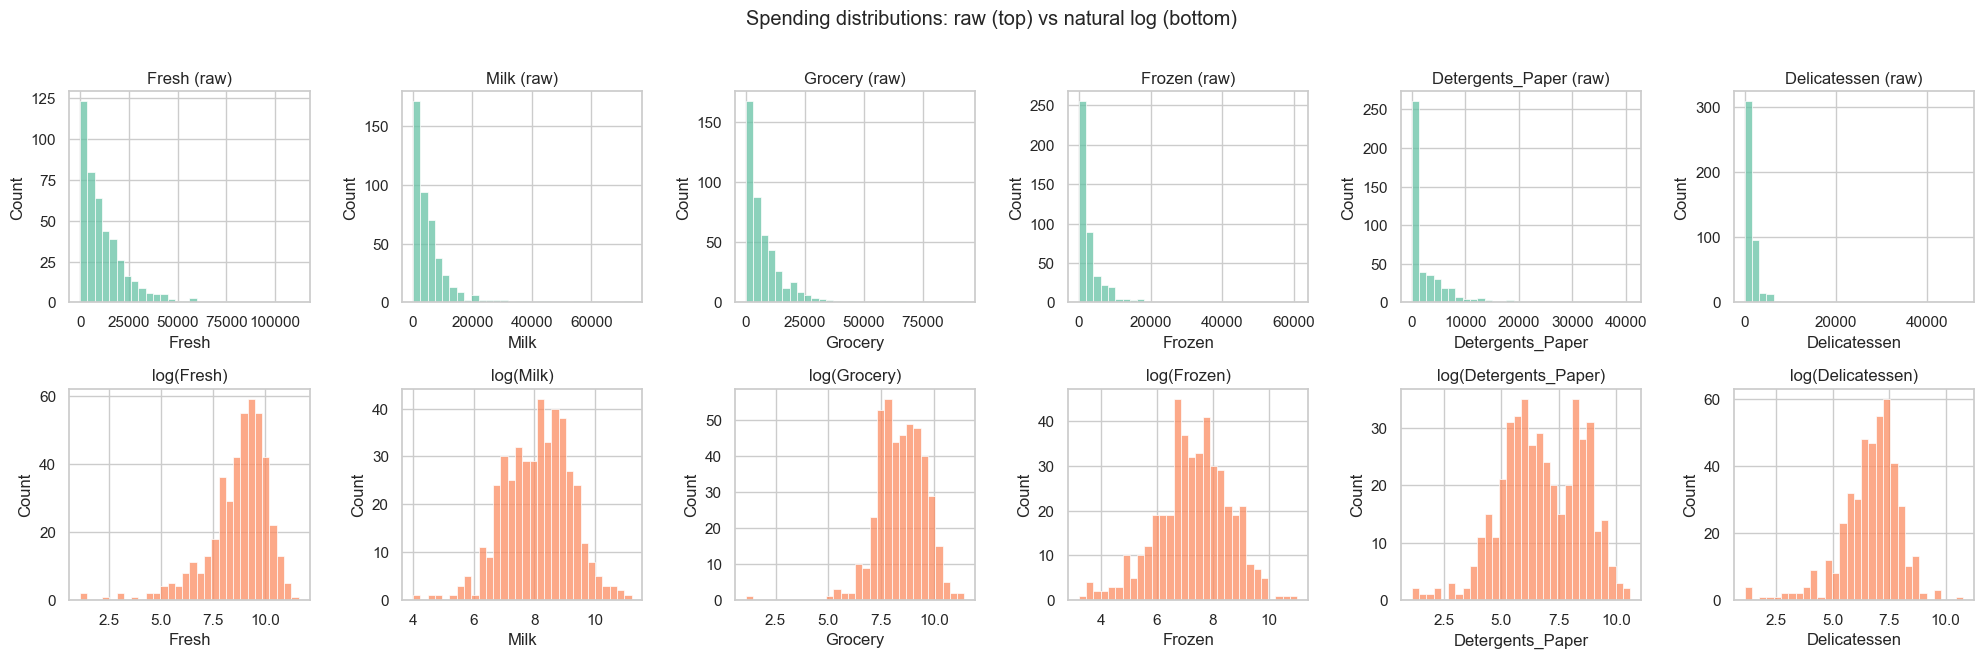

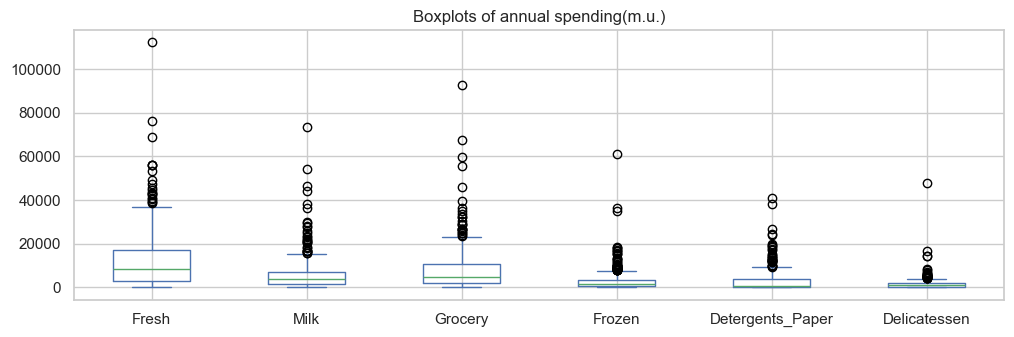

In [182]:
### Distributions: histograms and boxplots
fig, axes = plt.subplots(2, 6, figsize=(20, 6.5))
for j, col in enumerate(SPEND):
    sns.histplot(wholesale[col], bins=30, ax=axes[0, j], color="#66c2a5"); axes[0, j].set_title(f"{col} (raw)")
    sns.histplot(np.log(wholesale[col]), bins=30, ax=axes[1, j], color="#fc8d62"); axes[1, j].set_title(f"log({col})")
plt.suptitle("Spending distributions: raw (top) vs natural log (bottom)", y=1.01)
plt.tight_layout(); plt.show()
wholesale[SPEND].plot.box(figsize=(12, 3.5), title="Boxplots of annual spending(m.u.)")
plt.show()


**Explanation.** 
-   On the raw scale every category has a long right tail and many boxplot points beyond the whiskers. These are a few very large customers. 
-   On the **log scale** the distributions become roughly symmetric and bell-shaped, apart from a handful of customers with tiny spending (as low as 3 m.u.) that now appear on the left. This suggests **spending works multiplicatively** (large and small customers differ by factors, not fixed amounts), so a **log transform** is a natural choice before clustering .


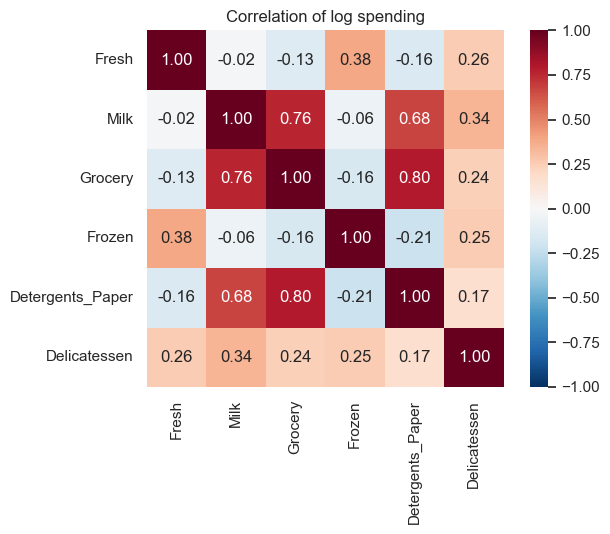

In [183]:

### Correlation between spending categories
plt.figure(figsize=(7, 5.5))
sns.heatmap(np.log(wholesale[SPEND]).corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation of log spending"); plt.tight_layout() 
plt.show()

**Explanation.** 
-   **Grocery, Detergents_Paper and Milk are strongly correlated** (r ≈ 0.7–0.8 on the log scale): customers who buy a lot of one tend to buy a lot of the others. That is the profile of a **shop**. 
-   **Fresh and Frozen** correlate with each other but not with that group: the profile of a **kitchen** (restaurants, hotels). These two "bundles" are the main structure in the data and hint at at least two natural segments.

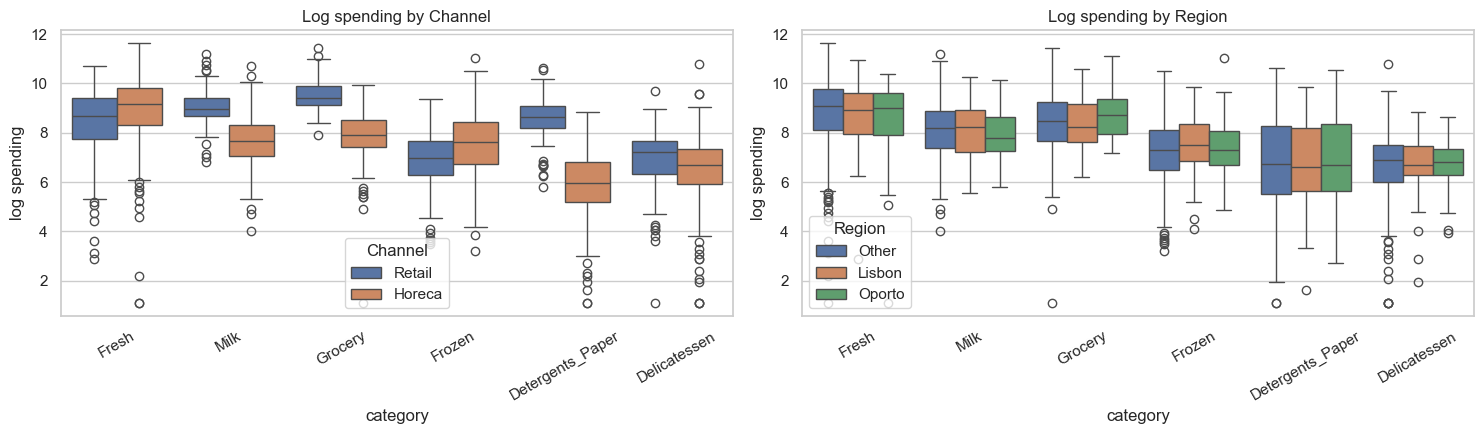

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Channel_name,,,,,,
Horeca,"9,581.500","2,157.000","2,684.000","2,057.500",385.500,821.000
Retail,"5,993.500","7,812.000","12,390.000","1,081.000","5,614.500","1,350.000"


In [184]:
###  Spending by Channel and Region
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
long = np.log(wholesale[SPEND]).assign(Channel=wholesale["Channel_name"]).melt(id_vars="Channel", var_name="category", value_name="log spending")
sns.boxplot(data=long, x="category", y="log spending", hue="Channel", ax=axes[0]); axes[0].set_title("Log spending by Channel")
long_r = np.log(wholesale[SPEND]).assign(Region=wholesale["Region_name"]).melt(id_vars="Region", var_name="category", value_name="log spending")
sns.boxplot(data=long_r, x="category", y="log spending", hue="Region", ax=axes[1]); axes[1].set_title("Log spending by Region")
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
wholesale.groupby("Channel_name")[SPEND].median()

**Explanation**
- **Channel separates spending strongly.** Retail customers spend far more on **Grocery** (median about 12,400 vs 2,700 m.u.), **Milk** and especially **Detergents_Paper** (about 6,000 vs 400). Horeca customers spend more on **Fresh** and **Frozen**.
- **Region makes little difference.** The three regions have very similar spending distributions, so region is unlikely to define segments.
- **Implication:** the segments we find should be compared with Channel. If they match it closely, clustering mostly rediscovers Channel; if not, it reveals new behaviour.

Explained variance by component: [0.44  0.271 0.108 0.101 0.049 0.031]
PC1 loadings: {'Fresh': np.float64(-0.1), 'Milk': np.float64(0.54), 'Grocery': np.float64(0.57), 'Frozen': np.float64(-0.14), 'Detergents_Paper': np.float64(0.55), 'Delicatessen': np.float64(0.21)}
PC2 loadings: {'Fresh': np.float64(0.59), 'Milk': np.float64(0.13), 'Grocery': np.float64(-0.01), 'Frozen': np.float64(0.59), 'Detergents_Paper': np.float64(-0.07), 'Delicatessen': np.float64(0.53)}


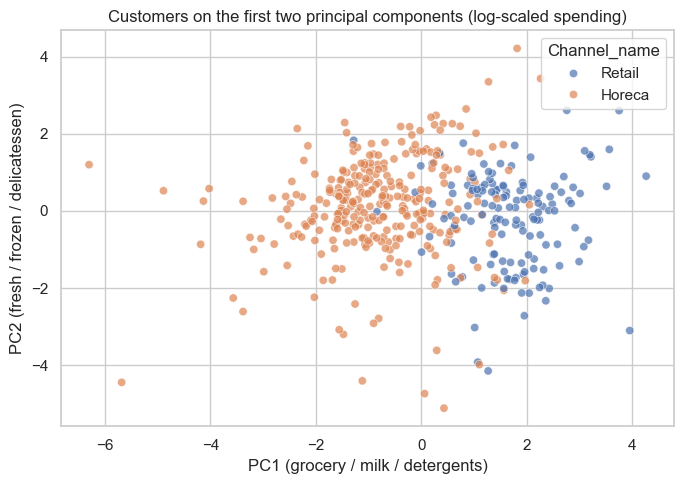

In [185]:

### A 2-D view of the data (PCA, for visualisation only)
X_log_scaled = StandardScaler().fit_transform(np.log(wholesale[SPEND]))
pca = PCA().fit(X_log_scaled)
P = pca.transform(X_log_scaled)[:, :2]
print("Explained variance by component:", np.round(pca.explained_variance_ratio_, 3))
print("PC1 loadings:", dict(zip(SPEND, np.round(pca.components_[0], 2))))
print("PC2 loadings:", dict(zip(SPEND, np.round(pca.components_[1], 2))))
plt.figure(figsize=(7, 5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=wholesale["Channel_name"], alpha=0.7)
plt.xlabel("PC1 (grocery / milk / detergents)"); plt.ylabel("PC2 (fresh / frozen / delicatessen)")
plt.title("Customers on the first two principal components (log-scaled spending)"); plt.tight_layout() 
plt.show()

**Explanation.** 
-   The first two components explain about **71%** of the variance (44% + 27%). **PC1** is the "shop" bundle (Milk, Grocery, Detergents_Paper) and **PC2** the "kitchen" bundle (Fresh, Frozen, Delicatessen). 
-   Retail customers sit mostly to the right (high PC1) and Horeca customers to the left, but **the two groups overlap and there is no wide empty gap**. We should expect clusters that are real but **not sharply separated**.

In [186]:

##Data preparation (with justification)
### Missing values and duplicates
wholesale.isnull()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Channel_name,Region_name
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
435,False,False,False,False,False,False,False,False,False,False
436,False,False,False,False,False,False,False,False,False,False
437,False,False,False,False,False,False,False,False,False,False
438,False,False,False,False,False,False,False,False,False,False


In [187]:

### Missing values and duplicates
print("Missing values per column:\n", wholesale[SPEND + ["Channel", "Region"]].isna().sum().to_string())
print("\nNumber of duplicate rows = %d" % wholesale[SPEND + ["Channel", "Region"]].duplicated().sum())
print("Customers with zero spending in any category:", int((wholesale[SPEND] == 0).any(axis=1).sum()))

Missing values per column:
 Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
Channel             0
Region              0

Number of duplicate rows = 0
Customers with zero spending in any category: 0


**Explanation.** 
-   There are **no missing values, no duplicate customers and no zero spending values**, so no rows are removed or imputed. 
-   The absence of zeros also means the log transform can be applied directly.

In [188]:
##Outliers (Z-score method)
Z_raw = (wholesale[SPEND] - wholesale[SPEND].mean()) / wholesale[SPEND].std()
logS = np.log(wholesale[SPEND])
Z_log = (logS - logS.mean()) / logS.std()
print("Values with |Z| > 3 — raw scale:\n", (Z_raw.abs() > 3).sum().to_string())
print("Customers flagged on the raw scale: %d" % (Z_raw.abs() > 3).any(axis=1).sum())
print("\nValues with |Z| > 3 — log scale:\n", (Z_log.abs() > 3).sum().to_string())
print("Customers flagged on the log scale: %d" % (Z_log.abs() > 3).any(axis=1).sum())

Values with |Z| > 3 — raw scale:
 Fresh                7
Milk                 9
Grocery              7
Frozen               6
Detergents_Paper    10
Delicatessen         4
Customers flagged on the raw scale: 26

Values with |Z| > 3 — log scale:
 Fresh               6
Milk                2
Grocery             2
Frozen              1
Detergents_Paper    3
Delicatessen        8
Customers flagged on the log scale: 19


**Explanation**: 
-  We  Keep all customers, but work on the log scale.
- On the **raw scale**, **26 customers** have at least one |Z| > 3, all on the *high* side: very large buyers. On the **log scale**, **19** are flagged, and these are mostly customers with *tiny* spending in one category (for example 3 m.u. of Fresh or Delicatessen).
- These are **real customers, not errors**. Very large buyers are exactly the accounts a distributor cares most about, so deleting them would distort the segmentation.
- Instead of deleting them we **reduce their influence** with the log transform (4.3). We check whether they change the results in a sensitivity analysis (Step 10), and DBSCAN (Step 8) flags them explicitly as "noise" customers.



In [189]:
### Transformation: log + standardisation
skew_tbl = pd.DataFrame({"skewness raw": wholesale[SPEND].skew(), "skewness after log": np.log(wholesale[SPEND]).skew()})
skew_tbl

,skewness raw,skewness after log
Fresh,2.561,-1.630
Milk,4.054,-0.227
Grocery,3.587,-0.740
Frozen,5.908,-0.361
Detergents_Paper,3.632,-0.272
Delicatessen,11.152,-1.177


**Decision** 
-** use log(spending), then standardise each category (mean 0, sd 1).**
- **Log transform:** skewness falls from 2.6–11.2 to between −1.6 and −0.2. Distances then reflect **relative** differences ("buys twice as much") rather than absolute ones, which suits customers of very different sizes. Without it, a few huge accounts would dominate every distance calculation.
- **Standardisation:** after the log, the categories still have different spreads. Standardising gives each category **equal weight**, so the clustering is driven by the whole spending pattern, not by the category with the largest numbers.
- These choices are tested in Step 10 by clustering the raw data instead.

### Feature selection
**Decision: cluster on the six spending columns only.** Channel and Region are categorical *labels of the customer*, not spending behaviour, and the task asks for segments "by spending behaviour". Keeping them out also lets us use Channel as an **independent check**: if the clusters match Channel partly without being told about it, that supports their validity.

In [190]:

X = X_log_scaled            # final clustering input: 440 customers × 6 standardised log-spending features
print("Clustering matrix:", X.shape)

Clustering matrix: (440, 6)


### Distance measure
k-means, Ward linkage, DBSCAN and the silhouette all use **Euclidean distance**. After log + standardisation, Euclidean distance compares customers' whole spending profiles on an equal footing. k-medoids is run with **Manhattan distance** , as a more outlier-robust alternative.


### Short data report

| Aspect | Finding | Decision / implication |
|---|---|---|
| Size & type | 440 customers; 6 continuous spending attributes (m.u. per year) + 2 categorical (Channel, Region) | Small enough for all three clustering families, including hierarchical |
| Data quality | No missing values, no duplicates, no zeros | No rows removed or imputed |
| Distribution | All spending strongly right-skewed (skewness 2.6–11.2); a few very large customers | **Log transform** (skewness then −1.6 to −0.2) |
| Scale | Categories differ greatly in magnitude and spread | **Standardise** after the log so each category counts equally |
| Outliers | 26 customers with \|Z\| > 3 on the raw scale (19 on the log scale); genuine accounts | Kept; influence reduced by the log; checked in Step 10; DBSCAN flags them |
| Correlation | Grocery–Milk–Detergents_Paper strongly correlated ("shop" bundle); Fresh–Frozen ("kitchen" bundle) | Expect segments along these two bundles |
| Channel / Region | Channel separates spending strongly; Region barely matters | Not used to cluster; used to interpret and validate the clusters |
| Structure (PCA) | 2 components explain 71%; groups overlap, no wide gaps | Expect real but not sharply separated clusters |

**Limitations of the data:** one distributor in Portugal, one year of spending, no information on customer size, profit margins or order frequency, and only 440 customers, so small segments rest on few customers.

---
## Cluster tendency: is there structure worth clustering?.

The **Hopkins statistic** compares (a) distances from real customers to their nearest real neighbour with (b) distances from **uniformly random points** to their nearest real customer. **H ≈ 0.5** means the data is as random as uniform noise. **H close to 1** means the real points are much closer to each other than random points are to them, i.e. the data is **clustered**.

H depends on the random sample, so we compute it **20 times** and report the mean and standard deviation. We compare three versions: the raw data, the prepared data (log-scaled), and truly uniform data of the same size as a reference.

In [191]:

def calculate_hopkins(X, sampling_ratio=0.3, seed=0):
    """Hopkins statistic, using a seeded random generator."""
    rng = np.random.default_rng(seed)
    X = np.asarray(X); n, d = X.shape; r = max(1, int(sampling_ratio * n))
    idx = rng.choice(n, r, replace=False)
    X_remaining = np.delete(X, idx, axis=0)
    x_dist, _ = NearestNeighbors(n_neighbors=1).fit(X_remaining).kneighbors(X[idx])
    simulated = rng.uniform(X.min(axis=0), X.max(axis=0), (r, d))
    y_dist, _ = NearestNeighbors(n_neighbors=1).fit(X).kneighbors(simulated)
    return y_dist.sum() / (x_dist.sum() + y_dist.sum())

uniform_ref = np.random.default_rng(SEED).uniform(size=X.shape)
X_raw_scaled = StandardScaler().fit_transform(wholesale[SPEND])
hop = {}
for name, data in [("Raw spending (standardised)", X_raw_scaled), ("Prepared: log + standardised", X), ("Uniform random reference", uniform_ref)]:
    vals = [calculate_hopkins(data, seed=s) for s in range(20)]
    hop[name] = {"Hopkins mean": np.mean(vals), "Hopkins sd": np.std(vals)}
pd.DataFrame(hop).T

,Hopkins mean,Hopkins sd
Raw spending (standardised),0.929,0.008
Prepared: log + standardised,0.794,0.010
Uniform random reference,0.485,0.005


**Explanation**
- **The prepared data has a clear cluster tendency:** H ≈ **0.79 ± 0.01**, well above the **0.49** of uniformly random data. So there is non-random structure, and it is worth clustering.
- **The raw data scores even higher (H ≈ 0.93), but that is misleading.** A few huge customers stretch the bounding box from which random points are drawn, so most random points land in empty space far from any customer, which inflates H. This is a known weakness of the Hopkins statistic with skewed data and outliers, and another reason to use the log scale.
- **H ≈ 0.80 says structure exists, not that it is sharply separated.** Together with the overlapping PCA picture (Step 3.5), we should expect clusters of moderate quality (silhouette values around 0.2–0.3, not 0.7).


## Partitioning methods: k-means and k-medoids

### Choosing k for k-means
* We combine the **SSE elbow** with three quality indices and a **stability** check:
- **Silhouette** : from −1 to 1, higher is better. It measures cohesion and separation together.
- **Davies–Bouldin:** the average similarity of each cluster to its most similar one. **Lower** is better.
- **Calinski–Harabasz:** between-cluster vs within-cluster dispersion. **Higher** is better.
- **Bootstrap stability:** recluster 30 bootstrap samples and measure agreement with the full-data solution (adjusted Rand index, ARI: 1 = identical, 0 = chance). Stable clusters are more trustworthy.

,SSE,silhouette,Davies-Bouldin,Calinski-Harabasz,stability (mean ARI),cluster sizes
k,,,,,,
2,"1,847.980",0.290,1.353,187.721,0.897,"[252, 188]"
3,"1,558.047",0.258,1.346,151.733,0.785,"[211, 148, 81]"
4,"1,391.926",0.188,1.542,130.314,0.600,"[129, 132, 61, 118]"
5,"1,271.309",0.191,1.489,117.080,0.536,"[90, 97, 54, 99, 100]"
6,"1,178.576",0.192,1.452,107.631,0.578,"[90, 84, 82, 55, 111, 18]"
7,"1,090.520",0.189,1.424,102.539,0.593,"[107, 90, 40, 95, 50, 35, 23]"
8,"1,026.923",0.194,1.391,96.940,0.607,"[77, 117, 48, 11, 48, 36, 81, 22]"


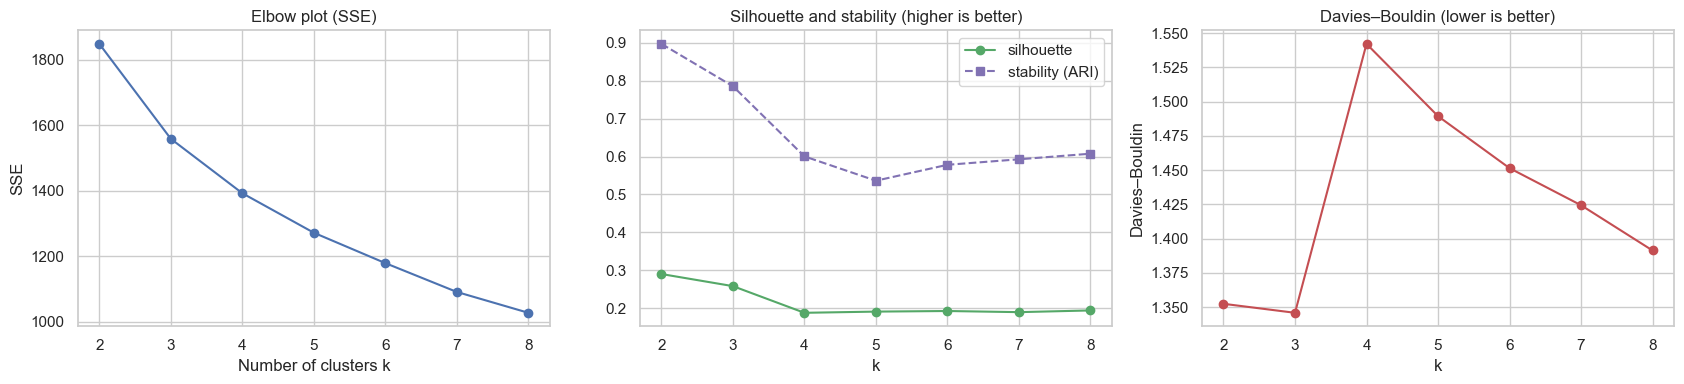

In [192]:
ks = range(2, 9)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    lab = km.labels_
    rng = np.random.default_rng(SEED); aris = []
    for b in range(30):
        idx = rng.choice(len(X), len(X), replace=True)
        aris.append(adjusted_rand_score(lab, KMeans(n_clusters=k, n_init=10, random_state=b).fit(X[idx]).predict(X)))
    rows.append({"k": k, "SSE": km.inertia_, "silhouette": silhouette_score(X, lab), "Davies-Bouldin": davies_bouldin_score(X, lab),
                 "Calinski-Harabasz": calinski_harabasz_score(X, lab), "stability (mean ARI)": np.mean(aris),
                 "cluster sizes": np.bincount(lab).tolist()})
k_tbl = pd.DataFrame(rows).set_index("k")
display(k_tbl)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(list(ks), k_tbl["SSE"], "bo-"); axes[0].set(xlabel="Number of clusters k", ylabel="SSE", title="Elbow plot (SSE)")
axes[1].plot(list(ks), k_tbl["silhouette"], "go-", label="silhouette"); axes[1].plot(list(ks), k_tbl["stability (mean ARI)"], "ms--", label="stability (ARI)")
axes[1].set(xlabel="k", title="Silhouette and stability (higher is better)"); axes[1].legend()
axes[2].plot(list(ks), k_tbl["Davies-Bouldin"], "ro-"); axes[2].set(xlabel="k", ylabel="Davies–Bouldin", title="Davies–Bouldin (lower is better)")
plt.tight_layout()
plt.show()


**Choosing k: what the evidence says**
- **The elbow is soft.** SSE drops most from k = 2 to 3 (1,848 → 1,558) and then decreases steadily, with no sharp elbow. That is typical of overlapping clusters.
- **k = 2 is statistically strongest**: highest silhouette (0.290), highest Calinski–Harabasz (188) and highest stability (ARI 0.90).
- **k = 3 is a close second**: silhouette 0.258, the *lowest* Davies–Bouldin (1.346), and still good stability (ARI 0.79). From k = 4 onwards every index gets worse: silhouette ≈ 0.19, stability ≈ 0.54–0.61.
- **Decision: k = 3.** k = 2 essentially reproduces Channel ("kitchens vs shops"). k = 3 keeps almost the same quality and stability but splits out a distinct, commercially meaningful group . The k = 2 split is kept as the robust backbone, and Step 10 shows the three segments nest inside it.

In [193]:

K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
labels_km = kmeans.labels_
centroids_mu = pd.DataFrame(np.exp(StandardScaler().fit(np.log(wholesale[SPEND])).inverse_transform(kmeans.cluster_centers_)), columns=SPEND)
print("k-means cluster sizes:", np.bincount(labels_km))
print("Centroids translated back to m.u. (geometric-mean spending per cluster):")
centroids_mu.round(0)

k-means cluster sizes: [211 148  81]
Centroids translated back to m.u. (geometric-mean spending per cluster):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,"7,928.000","1,513.000","1,972.000","1,978.000",243.000,600.000
1,"11,322.000","7,942.000","10,441.000","2,177.000","2,740.000","1,893.000"
2,"1,077.000","5,614.000","9,729.000",346.000,"3,254.000",316.000


### Silhouette plot for k-means (k = 3)
The silhouette of each *individual* customer shows which clusters are well defined and which customers sit between clusters.

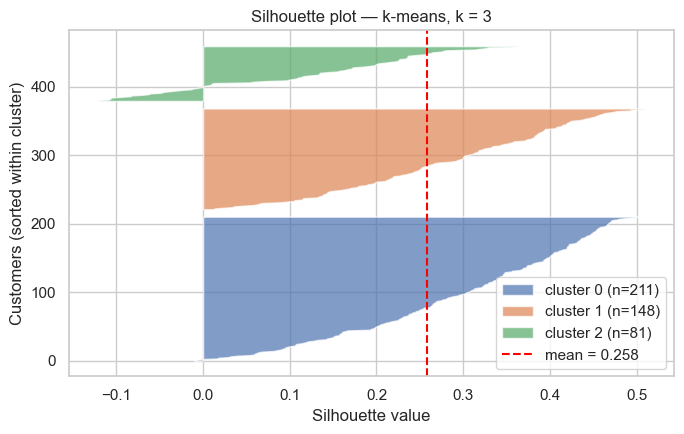

Share of customers with negative silhouette (probably in the wrong cluster): 5.5%
Mean silhouette by cluster: {0: 0.295, 1: 0.283, 2: 0.116}


In [194]:
sil_vals = silhouette_samples(X, labels_km)
fig, ax = plt.subplots(figsize=(7, 4.5)); y0 = 0
for c in range(K):
    v = np.sort(sil_vals[labels_km == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.7, label=f"cluster {c} (n={len(v)})"); y0 += len(v) + 10
ax.axvline(sil_vals.mean(), color="red", ls="--", label=f"mean = {sil_vals.mean():.3f}")
ax.set(xlabel="Silhouette value", ylabel="Customers (sorted within cluster)", title="Silhouette plot — k-means, k = 3"); ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print("Share of customers with negative silhouette (probably in the wrong cluster): %.1f%%" % (100 * (sil_vals < 0).mean()))
print("Mean silhouette by cluster:", pd.Series(sil_vals).groupby(labels_km).mean().round(3).to_dict())

**Interpretation.** The average silhouette is **0.258**. Two segments are reasonably well defined (mean silhouettes 0.30 and 0.28). The third (81 customers) is looser (0.12): its members are more varied. Only **5.5%** of customers have a negative silhouette, meaning they would fit slightly better in a neighbouring cluster. So most assignments are sensible, but the boundaries are soft. This matches the overlapping PCA picture and the Hopkins value of 0.79.

###  k-medoids (robust partitioning)
"k-means vs k-medoids" (the `simple_kmedoids` function with Manhattan distance).* k-medoids uses **actual customers** as cluster centres and Manhattan distance, so it is less affected by extreme customers. Its result can therefore be compared with k-means as a robustness check. Random initialisation can give different answers, so we run 20 starts and keep the solution with the smallest total distance.

In [195]:

def simple_kmedoids(X, k, max_iter=100, rng=None):
    """k-medoids, Manhattan distance; returns labels, medoid indices and total cost."""
    rng = rng or np.random.default_rng()
    n = X.shape[0]
    medoid_idx = rng.choice(n, k, replace=False)
    D = np.abs(X[:, None, :] - X[None, :, :]).sum(axis=2)      # all pairwise Manhattan distances
    for _ in range(max_iter):
        labels = np.argmin(D[:, medoid_idx], axis=1)
        new_idx = medoid_idx.copy()
        for i in range(k):
            members = np.where(labels == i)[0]
            if len(members):
                new_idx[i] = members[np.argmin(D[np.ix_(members, members)].sum(axis=1))]
        if np.all(new_idx == medoid_idx):
            break
        medoid_idx = new_idx
    labels = np.argmin(D[:, medoid_idx], axis=1)
    return labels, medoid_idx, D[np.arange(n), medoid_idx[labels]].sum()

rng = np.random.default_rng(SEED)
best = min((simple_kmedoids(X, K, rng=rng) for _ in range(20)), key=lambda t: t[2])
labels_kmed, medoid_idx, _ = best
print("k-medoids cluster sizes:", np.bincount(labels_kmed))
print(f"Silhouette: {silhouette_score(X, labels_kmed):.3f} | agreement with k-means (ARI): {adjusted_rand_score(labels_km, labels_kmed):.3f}")
print("The medoids are real customers:")
wholesale.loc[medoid_idx, SPEND + ["Channel_name", "Region_name"]]

k-medoids cluster sizes: [190 128 122]
Silhouette: 0.178 | agreement with k-means (ARI): 0.363
The medoids are real customers:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Channel_name,Region_name
244,6202,7775,10817,1183,3143,1970,Horeca,Lisbon
135,6300,1289,2591,1170,199,326,Horeca,Other
118,20049,1891,2362,5343,411,933,Horeca,Other


**Interpretation.** 
-   k-medoids (Manhattan distance) gives a clearly **weaker** solution: silhouette **0.178** vs 0.258 for k-means, and only moderate agreement with k-means (ARI 0.36). All three medoids are Horeca customers, and its third cluster is not the distinct "low-fresh" group that k-means finds.
-    Its usual advantage, robustness to outliers, matters less here because the **log transform has already tamed the extreme values**. Its interpretability advantage (a real customer represents each cluster) is useful for communication, but on quality the evidence favours k-means for this prepared data.

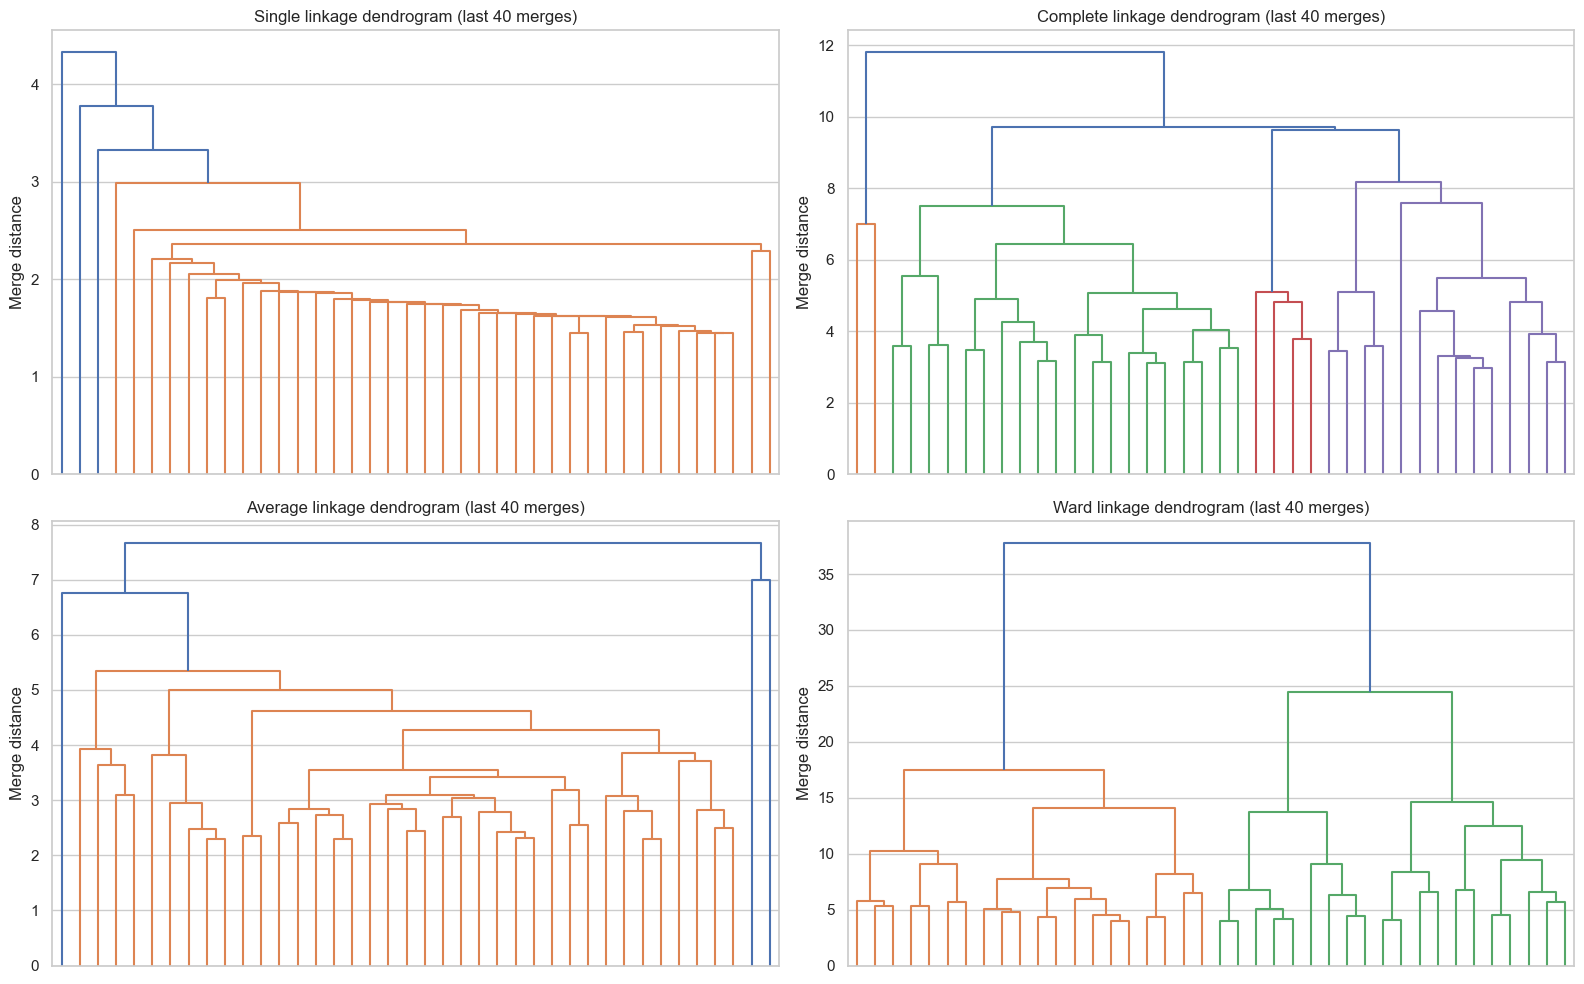

,linkage,k,cophenetic corr.,silhouette,cluster sizes
0,single,2,0.658,0.585,"[439, 1]"
1,single,3,0.658,0.519,"[438, 1, 1]"
2,single,4,0.658,0.509,"[437, 1, 1, 1]"
3,complete,2,0.475,0.579,"[438, 2]"
4,complete,3,0.475,0.137,"[311, 127, 2]"
5,complete,4,0.475,0.087,"[311, 71, 56, 2]"
6,average,2,0.756,0.579,"[438, 2]"
7,average,3,0.756,0.551,"[438, 1, 1]"
8,average,4,0.756,0.509,"[437, 1, 1, 1]"
9,ward,2,0.462,0.263,"[234, 206]"


In [196]:

## Hierarchical (agglomerative) clustering
fig, axes = plt.subplots(2, 2, figsize=(16, 10)); rows = []
for ax, method in zip(axes.ravel(), ["single", "complete", "average", "ward"]):
    Z = linkage(X, method=method)
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=None, truncate_mode="lastp", p=40)
    ax.set_title(f"{method.capitalize()} linkage dendrogram (last 40 merges)"); ax.set_ylabel("Merge distance")
    coph = cophenet(Z, pdist(X))[0]
    for k in [2, 3, 4]:
        lab = fcluster(Z, k, criterion="maxclust")
        rows.append({"linkage": method, "k": k, "cophenetic corr.": coph, "silhouette": silhouette_score(X, lab),
                     "cluster sizes": sorted(np.bincount(lab)[1:].tolist(), reverse=True)})
plt.tight_layout(); plt.show()
hier_tbl = pd.DataFrame(rows)
hier_tbl


**Interpretation: linkage choice matters enormously**
- **Single and average linkage** have the highest cophenetic correlations (0.66 and 0.76) and *very high* silhouettes (≈0.51–0.59). But their "clusters" are **437–439 customers plus 1–2 isolated individuals**. This is the **chaining effect** from the: single linkage merges through chains of close neighbours, so the only splits left are the few far-away customers. A high silhouette here is **misleading**: it rewards isolating outliers, not finding segments.
- **Complete linkage** is better balanced but unstable: it also isolates 2 customers and has low silhouettes (0.09–0.14) beyond k = 2.
- **Ward's linkage**, which minimises within-cluster variance like k-means, is the only one that gives **balanced, usable segments** (234 / 116 / 90 at k = 3, silhouette 0.235).
- **Lesson for evaluation:** quality indices must be read **together with cluster sizes**, never on their own.

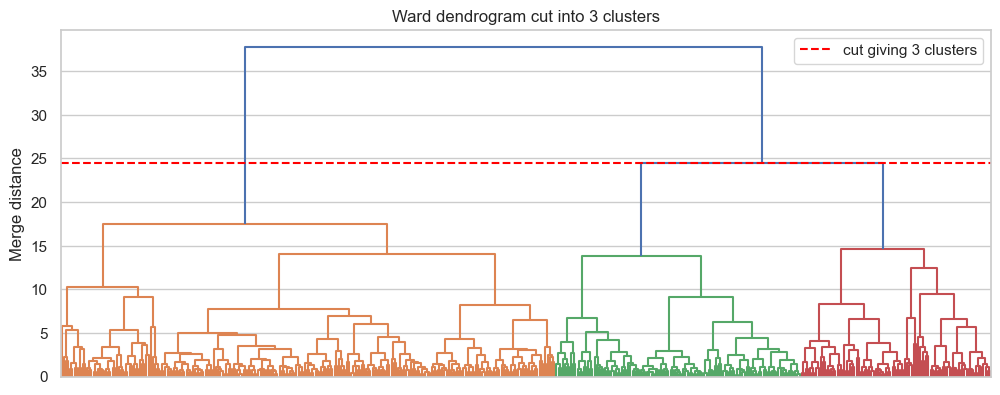

Ward (k=3) cluster sizes: [234 116  90] | silhouette 0.235 | agreement with k-means (ARI) 0.687


In [197]:
Z_ward = linkage(X, method="ward")
labels_ward = fcluster(Z_ward, K, criterion="maxclust") - 1
plt.figure(figsize=(12, 4.5))
dendrogram(Z_ward, no_labels=True, color_threshold=Z_ward[-K + 1, 2] - 1e-6)
plt.axhline(Z_ward[-K + 1, 2] - 1e-6, color="red", ls="--", label=f"cut giving {K} clusters"); plt.legend()
plt.title("Ward dendrogram cut into 3 clusters"); plt.ylabel("Merge distance"); plt.show()
print("Ward (k=3) cluster sizes:", np.bincount(labels_ward), f"| silhouette {silhouette_score(X, labels_ward):.3f}",
      f"| agreement with k-means (ARI) {adjusted_rand_score(labels_km, labels_ward):.3f}")

**Interpretation.** 
-   Cut into three clusters, Ward gives sizes 234 / 116 / 90 and a silhouette of **0.235**, slightly below k-means (0.258). It **agrees substantially with k-means** (ARI 0.69).
-    The **dendrogram is the big interpretability advantage**: it shows that the data first splits into two large branches (the kitchen-vs-shop split) and that the three-segment solution comes from subdividing one of them. That supports reading the k = 3 segments as sub-groups of a robust two-way split.

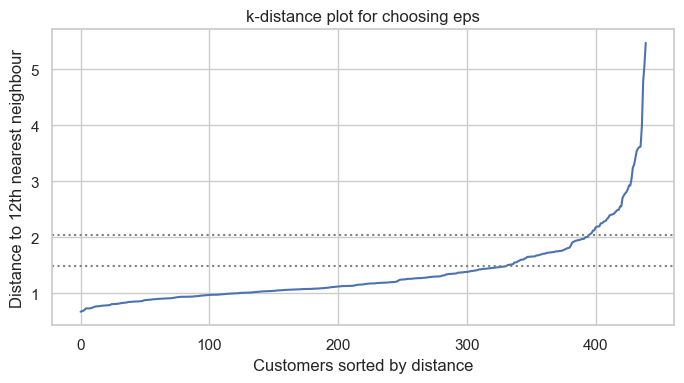

,min_samples,eps,clusters,noise customers,cluster sizes
0,4,0.800,4,206,"[220, 5, 6, 3]"
1,4,1.000,1,113,[327]
2,4,1.200,3,69,"[366, 4, 1]"
3,4,1.400,1,46,[394]
4,4,1.600,1,35,[405]
5,4,2.000,1,11,[429]
6,6,0.800,3,262,"[83, 88, 7]"
7,6,1.000,2,127,"[302, 11]"
8,6,1.200,1,80,[360]
9,6,1.400,1,53,[387]


In [198]:

## Density-based clustering: DBSCAN
k_dist = np.sort(NearestNeighbors(n_neighbors=12).fit(X).kneighbors(X)[0][:, -1])
plt.figure(figsize=(7, 4)); plt.plot(k_dist, "b-")
for q in [75, 90]: plt.axhline(np.percentile(k_dist, q), ls=":", color="grey")
plt.xlabel("Customers sorted by distance"); plt.ylabel("Distance to 12th nearest neighbour"); plt.title("k-distance plot for choosing eps")
plt.tight_layout(); plt.show()

grid = []
for ms in [4, 6, 8, 12]:
    for eps in [0.8, 1.0, 1.2, 1.4, 1.6, 2.0]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        grid.append({"min_samples": ms, "eps": eps, "clusters": n_cl, "noise customers": int((lab == -1).sum()),
                     "cluster sizes": np.bincount(lab[lab >= 0]).tolist() if n_cl else []})
dbscan_grid = pd.DataFrame(grid)
dbscan_grid

**Interpretation: DBSCAN finds no density-separated segments.** 
-   The k-distance plot rises smoothly, with no clear knee. Across all 24 parameter combinations, DBSCAN produces either **one big cluster plus noise** (most settings), or two or more clusters only when eps is so small that **most customers become noise** (for example 290–345 noise customers out of 440). - -   In other words, customers form **one continuous dense cloud with a sparse fringe**, not separate dense islands. That agrees with the Hopkins and PCA findings: the structure is real but gradual.

DBSCAN (eps=1.6, min_samples=12): 1 cluster, 42 noise customers (9.5%)


,core customers (median m.u.),noise customers (median m.u.)
Fresh,"8,752.000","1,912.000"
Milk,"3,664.000","2,183.000"
Grocery,"4,744.000","5,208.000"
Frozen,"1,668.000",818.000
Detergents_Paper,829.000,372.000
Delicatessen,994.000,210.000


Channel of noise customers: {'Horeca': 34, 'Retail': 8}


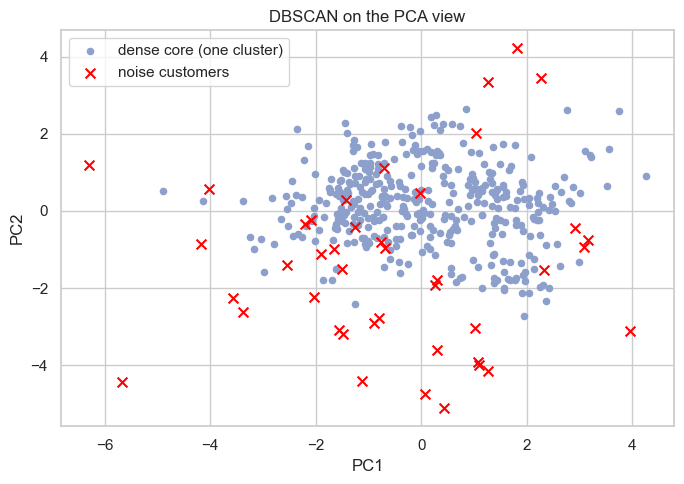

In [199]:
dbscan = DBSCAN(eps=1.6, min_samples=12).fit(X)
labels_db = dbscan.labels_
noise = labels_db == -1
print(f"DBSCAN (eps=1.6, min_samples=12): {len(set(labels_db)) - (-1 in labels_db)} cluster, {noise.sum()} noise customers ({100 * noise.mean():.1f}%)")
cmp = pd.DataFrame({"core customers (median m.u.)": wholesale.loc[~noise, SPEND].median(), "noise customers (median m.u.)": wholesale.loc[noise, SPEND].median()})
display(cmp.round(0))
print("Channel of noise customers:", wholesale.loc[noise, "Channel_name"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(P[~noise, 0], P[~noise, 1], c="#8da0cb", s=20, label="dense core (one cluster)")
ax.scatter(P[noise, 0], P[noise, 1], c="red", marker="x", s=50, label="noise customers")
ax.set(xlabel="PC1", ylabel="PC2", title="DBSCAN on the PCA view"); ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** 
-   With eps = 1.6 and min_samples = 12 (eps near the 90th percentile of the k-distance plot), DBSCAN keeps **398 customers in one dense core** and labels **42 (9.5%) as noise**. The noise customers are not simply "big spenders": their median spending is *lower* in most categories (for example Fresh 1,912 vs 8,752 m.u.), and 34 of the 42 are Horeca. 
-   These are customers with **unusual spending mixes**, such as tiny amounts in one category and normal amounts in others. DBSCAN therefore serves as a **partial clustering that flags exceptional accounts**, which the distributor may want to review individually, but it does not provide segments.

In [200]:

## Comparing quality and interpretability
###Quality
def stability(fit_predict, k_runs=30):
    rng = np.random.default_rng(SEED); full = fit_predict(X); aris = []
    for b in range(k_runs):
        idx = rng.choice(len(X), len(X), replace=True)
        lab_b = np.full(len(X), -2); lab_b[idx] = fit_predict(X[idx])     # labels for sampled customers
        seen = np.unique(idx); aris.append(adjusted_rand_score(full[seen], lab_b[seen]))
    return np.mean(aris)

solutions = {
    "k-means (k=3)": (labels_km, lambda A: KMeans(K, n_init=10, random_state=SEED).fit_predict(A)),
    "k-medoids (k=3)": (labels_kmed, None),
    "Ward hierarchical (k=3)": (labels_ward, lambda A: fcluster(linkage(A, "ward"), K, "maxclust")),
    "Average-link hierarchical (k=3)": (fcluster(linkage(X, "average"), K, "maxclust") - 1, lambda A: fcluster(linkage(A, "average"), K, "maxclust")),
    "DBSCAN (eps=1.6, min_samples=12)": (labels_db, lambda A: DBSCAN(eps=1.6, min_samples=12).fit_predict(A)),
}
rows = []
for name, (lab, fp) in solutions.items():
    valid = lab >= 0; n_cl = len(set(lab[valid]))
    rows.append({"method": name, "clusters": n_cl, "sizes": np.bincount(lab[valid]).tolist(), "noise": int((~valid).sum()),
                 "silhouette": silhouette_score(X[valid], lab[valid]) if n_cl > 1 else np.nan,
                 "Davies-Bouldin": davies_bouldin_score(X[valid], lab[valid]) if n_cl > 1 else np.nan,
                 "Calinski-Harabasz": calinski_harabasz_score(X[valid], lab[valid]) if n_cl > 1 else np.nan,
                 "stability (ARI)": stability(fp) if fp else np.nan,
                 "agreement with k-means (ARI)": adjusted_rand_score(labels_km, lab),
                 "agreement with Channel (ARI)": adjusted_rand_score(wholesale["Channel"], lab)})
quality = pd.DataFrame(rows).set_index("method")
quality

,clusters,sizes,noise,silhouette,Davies-Bouldin,Calinski-Harabasz,stability (ARI),agreement with k-means (ARI),agreement with Channel (ARI)
method,,,,,,,,,
k-means (k=3),3,"[211, 148, 81]",0,0.258,1.346,151.733,0.793,1.000,0.341
k-medoids (k=3),3,"[190, 128, 122]",0,0.178,1.637,124.167,NaN,0.363,0.255
Ward hierarchical (k=3),3,"[234, 116, 90]",0,0.235,1.409,136.301,0.539,0.687,0.412
Average-link hierarchical (k=3),3,"[438, 1, 1]",0,0.551,0.301,9.465,0.563,-0.003,-0.005
"DBSCAN (eps=1.6, min_samples=12)",1,[398],42,NaN,NaN,NaN,0.912,0.029,-0.030


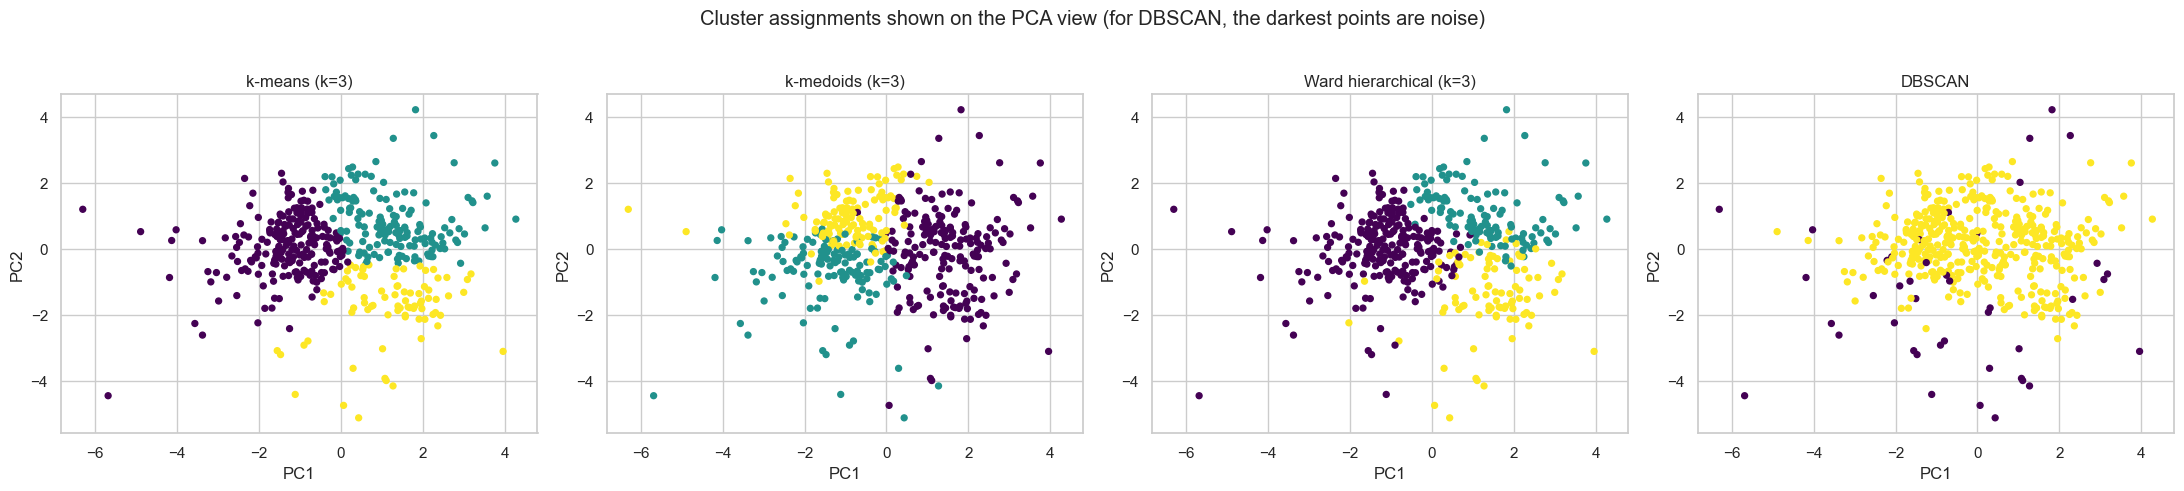

In [201]:

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, (name, lab) in zip(axes, [("k-means (k=3)", labels_km), ("k-medoids (k=3)", labels_kmed),
                                  ("Ward hierarchical (k=3)", labels_ward), ("DBSCAN", labels_db)]):
    sc = ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="viridis", s=18); ax.set(title=name, xlabel="PC1", ylabel="PC2")
plt.suptitle("Cluster assignments shown on the PCA view (for DBSCAN, the darkest points are noise)", y=1.02)
plt.tight_layout() 
plt.show()

### Comparison: quality **and** interpretability

| Family | Method | Quality (evidence) | Interpretability | Verdict |
|---|---|---|---|---|
| **Partitioning** | **k-means (k = 3)** | Silhouette **0.258**, Davies–Bouldin **1.35** (best), Calinski–Harabasz **152** (best); **stability 0.79** | **High**: each centroid is a "typical spending profile" in m.u.; balanced sizes (211 / 148 / 81) | ✅ **Best overall: used for the final segments** |
| Partitioning | k-medoids (k = 3) | Silhouette 0.178, Davies–Bouldin 1.64; ARI 0.36 with k-means | High (a medoid is a real customer) but the clusters are less distinct | Weaker on this data |
| **Hierarchical** | **Ward (k = 3)** | Silhouette 0.235, Davies–Bouldin 1.41; stability 0.54; ARI 0.69 with k-means | **High**: the dendrogram shows how segments nest (2 branches → 3) | ✅ Good confirmation of k-means |
| Hierarchical | Average / single link | Silhouette 0.55 *but* clusters of 438 + 1 + 1 | **Low**: it only isolates outliers (chaining) | ❌ Misleading indices |
| **Density-based** | **DBSCAN** | One cluster + 42 noise points in every reasonable setting; stable (0.91) but no segments | **Medium**: noise points are interpretable as "exceptional accounts" | Useful for outliers, **not** for segmentation |

**Key points**
1. **Partitioning wins on quality and practical interpretability.** k-means gives the best scores on all three indices among the balanced solutions, and the most stable segments.
2. **Hierarchical clustering confirms the structure and explains it.** Ward agrees substantially with k-means, and the dendrogram shows the three segments are sub-groups of a robust two-way split. Other linkages show that a **good-looking index can hide a useless clustering**.
3. **Density-based clustering shows what the data does *not* have**: separate dense groups. It instead identifies a fringe of unusual customers.
4. **External check.** All partitioning and Ward solutions agree **partly** with Channel (ARI 0.26–0.41). The segments are related to customer type but are **not just a copy of it**. They capture spending behaviour that Channel alone misses, for example the Horeca customers inside the "grocery & household" and "large all-round" segments.


## Sensitivity analysis
We check whether the segmentation depends on our preparation choices:
1. **No log transform** (raw spending, standardised).
2. **Without the 42 DBSCAN noise customers**: we re-prepare and re-cluster the remaining 398 customers. Are the segments driven by extreme accounts?
3. **k = 2 vs k = 3:** do the three segments nest inside the two-segment split?

In [202]:
km_raw = KMeans(K, n_init=20, random_state=SEED).fit_predict(X_raw_scaled)
print("1) k-means on RAW (standardised) spending, k=3: sizes", np.bincount(km_raw).tolist(),
      f"| silhouette {silhouette_score(X_raw_scaled, km_raw):.3f} | agreement with our solution (ARI) {adjusted_rand_score(labels_km, km_raw):.3f}")

X_core = StandardScaler().fit_transform(np.log(wholesale.loc[~noise, SPEND]))     # re-prepare without the 42 noise customers
for k in [2, 3]:
    full_k = KMeans(k, n_init=20, random_state=SEED).fit_predict(X)
    core_k = KMeans(k, n_init=20, random_state=SEED).fit_predict(X_core)
    print(f"2) k={k}: agreement between the full-data segments and segments re-fitted without the noise customers (ARI) = "
          f"{adjusted_rand_score(full_k[~noise], core_k):.3f}")

labels_k2 = KMeans(2, n_init=20, random_state=SEED).fit_predict(X)
print("\n3) How the k=3 segments split the k=2 segments (rows = k=3 cluster, columns = k=2 cluster):")
pd.crosstab(pd.Series(labels_km, name="k=3 cluster"), pd.Series(labels_k2, name="k=2 cluster"))

1) k-means on RAW (standardised) spending, k=3: sizes [45, 393, 2] | silhouette 0.548 | agreement with our solution (ARI) 0.081
2) k=2: agreement between the full-data segments and segments re-fitted without the noise customers (ARI) = 0.960
2) k=3: agreement between the full-data segments and segments re-fitted without the noise customers (ARI) = 0.863

3) How the k=3 segments split the k=2 segments (rows = k=3 cluster, columns = k=2 cluster):


k=2 cluster,0,1
k=3 cluster,,
0,210,1
1,33,115
2,9,72


**Interpretation**
1. **The log transform is essential.** Clustering the *raw* spending gives sizes 45 / 393 / 2. Its silhouette is high (0.55), but it does so by isolating a few huge customers, like single linkage, and it bears almost no relation to our segments (ARI 0.08). Without the log, the segmentation would be driven by customer *size*, not spending *pattern*.
2. **Segments are not driven by the exceptional customers.** After removing the 42 DBSCAN noise customers and re-preparing the data, the **two-segment split is almost unchanged (ARI 0.96)** and the **three segments are largely reproduced (ARI 0.86)**.
3. **The three segments nest inside the two-segment split.** Segment 0 maps almost entirely (210 of 211) to one side of the k = 2 split, the "kitchen" side. Segments 1 and 2 come mostly from the other, "shop" side (115 of 148 and 72 of 81). k = 3 therefore **refines** the robust k = 2 structure rather than contradicting it.


## Naming the clusters and describing spending habits

### Cluster profiles
We describe each k-means segment by its **median spending** (m.u.), its spending relative to the median customer (an **index**: 1.0 = typical, 2.0 = twice the typical amount), the **share of its budget** spent on each category, and its **Channel/Region mix**.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,customers,total spend (median),% Retail
cluster,,,,,,,,,
0,"9,612.000","1,596.000","2,147.000","2,121.000",274.000,686.000,211,"18,480.000",1.000
1,"12,166.000","7,146.000","9,880.000","2,019.000","3,350.000","1,988.000",148,"45,620.000",61.000
2,"1,454.000","6,264.000","10,487.000",388.000,"4,196.000",436.000,81,"27,289.000",59.000


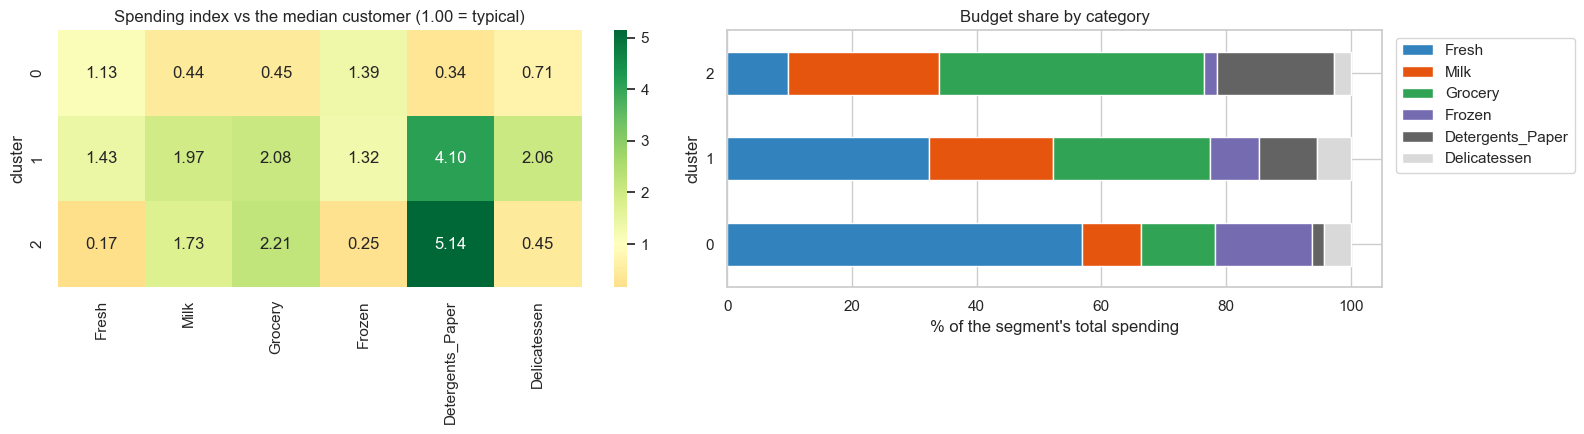

Region_name,Lisbon,Oporto,Other
cluster,,,
0,0.190,0.120,0.690
1,0.160,0.070,0.770
2,0.170,0.120,0.700


In [203]:
seg = wholesale.assign(cluster=labels_km)
profile = seg.groupby("cluster")[SPEND].median()
profile["customers"] = seg.groupby("cluster").size()
profile["total spend (median)"] = seg.assign(total=seg[SPEND].sum(axis=1)).groupby("cluster")["total"].median()
profile["% Retail"] = seg.groupby("cluster")["Channel"].apply(lambda s: (s == 2).mean() * 100)
display(profile.round(0))

index = profile[SPEND] / wholesale[SPEND].median()
share = seg.groupby("cluster")[SPEND].sum().pipe(lambda d: d.div(d.sum(axis=1), axis=0) * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.heatmap(index, annot=True, fmt=".2f", cmap="RdYlGn", center=1, ax=axes[0])
axes[0].set_title("Spending index vs the median customer (1.00 = typical)")
share.plot.barh(stacked=True, ax=axes[1], colormap="tab20c"); axes[1].set(xlabel="% of the segment's total spending", title="Budget share by category")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
pd.crosstab(seg["cluster"], seg["Region_name"], normalize="index").round(2)

**Reading the profiles** (index = segment median ÷ median of all customers)
- **Segment 0** (211 customers, **1% Retail**): spends **above average on Fresh (index 1.13) and Frozen (1.39)** but well below average on Milk (0.44), Grocery (0.45) and especially Detergents_Paper (0.34). It has the **smallest total spend** (median 18,480 m.u.). This is the profile of **restaurants, hotels and cafés cooking with fresh produce**.
- **Segment 1** (148 customers, 61% Retail): **above average in every category**: Milk 1.97, Grocery 2.08, Detergents_Paper 4.10, Delicatessen 2.06, and also Fresh 1.43 and Frozen 1.32. It has the **largest total spend** (median 45,620 m.u., about 2.5 times segment 0). These are **big, diverse buyers**: larger retailers and large hotels that buy a full range.
- **Segment 2** (81 customers, 59% Retail): very high **Grocery (2.21), Milk (1.73) and Detergents_Paper (5.14)** but **almost no Fresh (0.17) or Frozen (0.25)** and low Delicatessen (0.45). The median total is 27,289 m.u. This is the profile of **shops selling packaged goods and household products**, for example minimarkets, kiosks and convenience stores, plus Horeca outlets such as bars and cafés that buy groceries and drinks but don't cook.
- **Region** barely differs between segments (each is about 70% "Other"), confirming Step 3.4: segments reflect *what* customers buy, not *where* they are.

**Names given to the segments**

| Cluster | Name | Size | One-line description |
|---|---|---|---|
| 0 | **Fresh-food caterers** | 211 | Horeca kitchens: fresh and frozen food, little else |
| 1 | **Large all-round buyers** | 148 | Biggest accounts, above-average spending in every category |
| 2 | **Grocery & household specialists** | 81 | Packaged groceries, milk and detergents; almost no fresh or frozen |

In [204]:
SEGMENT_NAMES = {0: "Fresh-food caterers", 1: "Large all-round buyers", 2: "Grocery & household specialists"}
seg["segment"] = seg["cluster"].map(SEGMENT_NAMES)
seg.loc[noise, "flag"] = "exceptional account (DBSCAN noise)"
summary = seg.groupby("segment").agg(customers=("cluster", "size"), share_retail=("Channel", lambda s: (s == 2).mean()),
                                     exceptional_accounts=("flag", lambda s: s.notna().sum()))
summary

,customers,share_retail,exceptional_accounts
segment,,,
Fresh-food caterers,211,0.014,18
Grocery & household specialists,81,0.593,18
Large all-round buyers,148,0.615,6


### Spending habits and how to serve each segment

| Segment | Spending habits | How the distributor could serve it differently |
|---|---|---|
| **Fresh-food caterers** (211; 99% Horeca) | Budget concentrated on **Fresh and Frozen**; low grocery, milk and detergent purchases; smallest totals per customer, but the most customers (48% of the base) | **Frequent, reliable cold-chain deliveries** (early morning, several times a week); freshness guarantees; seasonal produce offers. **Cross-sell** detergents/paper and dairy as kitchen supplies (currently well below average) |
| **Large all-round buyers** (148; 61% Retail) | **High spending in every category**; the most valuable accounts (median total 45,620 m.u.) | **Key-account management**: a dedicated representative, volume discounts and contracts, full-range consolidated deliveries, priority stock allocation. Protect these accounts. Losing one costs about 2.5 times as much as losing a caterer |
| **Grocery & household specialists** (81; 59% Retail) | **Grocery, Milk and Detergents_Paper** dominate (Detergents_Paper index 5.1); almost **no fresh or frozen** | **Ambient (non-refrigerated) delivery routes** at lower cost and lower frequency; bulk and pallet pricing on packaged goods; shelf-ready packaging and promotions on household products. Fresh/frozen cross-selling is likely to fail, since these customers often lack cold storage, so focus on depth in packaged lines |
| *Exceptional accounts* (42 flagged by DBSCAN, spread across segments) | Unusual spending mixes (for example very low spending in one category) | Review **individually**: they may be new, partially lost or specialised customers, and a segment-wide policy may not suit them |


### Conclusions, limitations and responsible use

### Conclusions

1. **Data and preparation (Task 1).** 440 clean records with extremely skewed spending. A **log transform plus standardisation** was necessary: without it, clustering just separates a few huge customers. **Cluster tendency is clear but moderate** (Hopkins ≈ 0.79 vs 0.49 for random data).
2. **Comparison of clustering families (Task 2).** **Partitioning (k-means)** gives the best quality and the most actionable output. **Hierarchical (Ward)** confirms the same structure and explains it through the dendrogram, while single and average linkage show how indices can mislead (chaining). **Density-based (DBSCAN)** finds no separate dense groups, only one core and a fringe of 42 exceptional accounts.
3. **Segments (Task 3).** **Fresh-food caterers**, **large all-round buyers** and **grocery & household specialists**. They differ clearly in what they buy and how much, and they nest within a very robust "kitchens vs shops" split.
4. **Recommendation.** Use the segments to design **delivery routes (cold-chain vs ambient), account management and targeted offers**. Review exceptional accounts individually, and re-run the segmentation as new spending data arrives.

### Limitations
1. **Moderate separation.** The best silhouette values are about 0.26–0.29. The segments are useful summaries of a continuum of customers, not sharply distinct types. Customers near a boundary (5.5% have negative silhouettes) could reasonably belong to the neighbouring segment.
2. **One year, one distributor.** Spending may change over time. The segmentation should be refreshed with new data and the stability re-checked.
3. **Spending only.** There is no data on profit margins, order frequency, delivery cost or customer size, all of which matter for how to serve a customer.
4. **The choice of k is a judgement.** The indices favour k = 2. We chose k = 3 for business usefulness , and the k = 2 split remains a valid, more stable alternative.

### Responsible use
- Segments should **guide** offers and service levels, not be used to deny service or impose unfavourable terms on any customer.
- Treat the exceptional accounts flagged by DBSCAN **individually** rather than forcing them into a segment.
- Validate the recommendations with the sales team and a small pilot before changing pricing or delivery for a whole segment.